# 02 - Validación temporal

**Objetivo:** definir los cortes train / validación / test y verificar que cada tramo sea razonable (tamaño, tasa de fraude, proporción con identidad).

No se usa `train_test_split` aleatorio: en producción el modelo predice sobre el futuro, así que lo evaluamos de la misma forma.

In [6]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.validation import add_day, temporal_split, summarize_splits, TRAIN_END_DAY, VALID_END_DAY

sns.set_theme(style="whitegrid")
df = add_day(pd.read_parquet("../data/processed/train_merged.parquet"))
df.shape

(590540, 436)

## 1. Tasa de fraude por semana y cortes propuestos
Las líneas rojas son los cortes. Conviene que ningún pico quede partido justo en un corte.

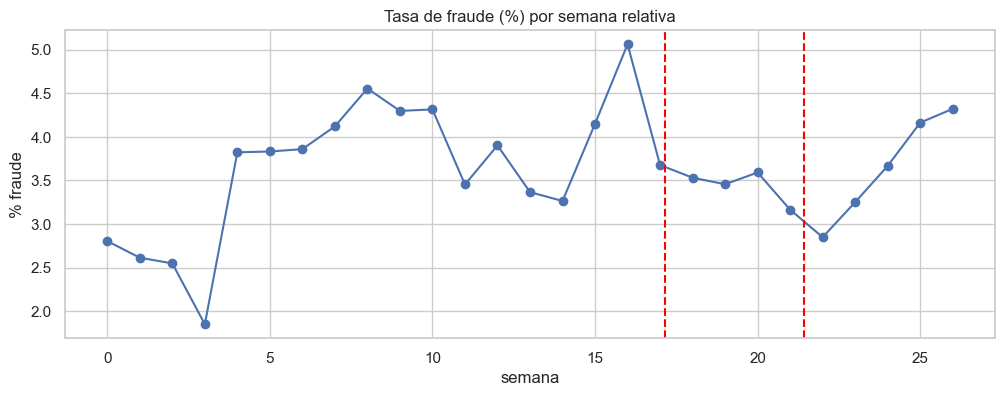

In [7]:
df["week"] = df["day"] // 7
weekly = df.groupby("week")["isFraud"].mean() * 100

fig, ax = plt.subplots(figsize=(12, 4))
weekly.plot(ax=ax, marker="o")
for cut in (TRAIN_END_DAY, VALID_END_DAY):
    ax.axvline(cut / 7, color="red", linestyle="--")
ax.set_title("Tasa de fraude (%) por semana relativa")
ax.set_xlabel("semana"); ax.set_ylabel("% fraude")
plt.show()

## 2. División y resumen por tramo

In [8]:
train, valid, test = temporal_split(df)
summarize_splits(train=train, valid=valid, test=test)

,filas,% del total,día_min,día_max,fraudes,tasa_fraude_%,%_con_identidad
split,,,,,,,
train,410601,69.53,1,119,14419,3.51,26.64
valid,85303,14.44,120,149,2962,3.47,17.72
test,94636,16.03,150,182,3282,3.47,20.86


## 3. Estabilidad de `has_identity` y `ProductCD` entre tramos
Si la composición cambia mucho entre train y test, el modelo puede degradarse por *drift*.

In [9]:
pd.concat({
    name: part["ProductCD"].value_counts(normalize=True).round(3)
    for name, part in {"train": train, "valid": valid, "test": test}.items()
}, axis=1)

,train,valid,test
ProductCD,,,
W,0.720,0.816,0.786
C,0.121,0.104,0.105
R,0.073,0.038,0.047
H,0.068,0.027,0.029
S,0.017,0.016,0.033


In [10]:
pd.concat({
    name: part.groupby("has_identity")["isFraud"].mean().round(4)
    for name, part in {"train": train, "valid": valid, "test": test}.items()
}, axis=1)

,train,valid,test
has_identity,,,
0,0.0214,0.0213,0.0187
1,0.0729,0.0970,0.0951


## 4. Decisiones y observaciones

**Cortes elegidos**
- Train: días 1-119 (69,5%) | Validación: 120-149 (14,4%) | Test: 150-182 (16,0%).
- Sin `gap_days` (= 0) por ahora. Se puede revisar si se sospecha fuga por tarjetas que aparecen a ambos lados de un corte.
- El pico de fraude de la semana 16 (~5,0%) queda completo dentro de train. El corte del día 120 cae en una zona calmada (semana 17, ~3,5%), por lo que no se parte ningún pico.

**Verificación de los tramos**
- La tasa de fraude es estable: 3,51% / 3,47% / 3,47%.
- Hay fraudes suficientes para evaluar con estabilidad: 2.962 en validación y 3.282 en test.

**Drift observado**
- `ProductCD`: la composición cambia. W pasa de 72% en train a 82% en validación y 79% en test, mientras que H (6,8% → 2,7%) y R (7,3% → 3,8%) se reducen a la mitad o menos.
- `has_identity`: la cobertura baja de 26,6% en train a 17,7% en validación y 20,9% en test. Además, la tasa de fraude del grupo con identidad sube de 7,3% (train) a ~9,6% (valid/test), mientras que la del grupo sin identidad se mantiene en ~2%.
- Ambos cambios se compensan a nivel global (por eso la tasa total no se mueve), pero el modelo verá una mezcla de población distinta a la de entrenamiento.

**Implicancias para el modelado**
- Evaluar las métricas también por segmento (`ProductCD`, `has_identity`), no solo en total.
- Cuidado con variables que dependan de la composición de la población: pueden degradarse fuera de tiempo.
- Reportar siempre resultados en validación y test temporales, nunca con cortes aleatorios.